## Vehicle Routing Problem (VRP) with VNS and GVNS

The objective of this project is to find the best routes for a fleet of vehicles that start from a depot, visit all customers once, and come back to the depot.

Each vehicle can serve a limited number of customers (its capacity).

The goal is to serve all customers while minimizing the total distance traveled.

We will use VNS and GVNS to find and compare optimized routes.

In [1]:
import random
import math
from itertools import combinations
import matplotlib.pyplot as plt

## 1. Define the problem

In [2]:
points = [
    (50, 50),                                  
    (20, 80), (30, 70), (15, 60), (25, 90),    
    (80, 80), (70, 70), (85, 60), (75, 90),    
    (20, 20), (30, 10), (15, 30), (40, 25),    
    (80, 20), (90, 35), (65, 15)               
]

NB_VEHICLES = 3
CAPACITY = 6      
PENALTY = 50     


def distance(a, b):
    return math.hypot(points[a][0] - points[b][0], points[a][1] - points[b][1])

## 2. Evaluation function

A solution is a list of routes. Example: `[[3, 5, 1], [2, 8], [4, 7, 6]]`

Each route starts and ends at the depot (0).

$$
f(S) = \text{Total Distance}(S) + \text{Capacity Penalty}(S)
$$

In [3]:
def route_length(route):

    path = [0] + route + [0]

    length = 0
    for i in range(len(path) - 1):
        length += distance(path[i], path[i + 1])

    return length


def evaluate(solution):

    total_distance = 0
    overload = 0

    for route in solution:
        total_distance += route_length(route)

        # Customers above the capacity
        if len(route) > CAPACITY:
            overload += len(route) - CAPACITY

    return total_distance + PENALTY * overload

## 3. Local Search function
Objective: Improve the solution by exploring its neighbors.

We use the **relocate** neighborhood: take one customer and put it in another position (in the same route or in another route).

In [4]:
def copy_solution(solution):
    return [route.copy() for route in solution]


def best_relocate(solution):

    best = copy_solution(solution)
    best_cost = evaluate(solution)

    for a in range(len(solution)):                    
        for i in range(len(solution[a])):             

            for b in range(len(solution)):            
                for j in range(len(solution[b]) + 1): 

                    neighbor = copy_solution(solution)

                    customer = neighbor[a].pop(i)
                    neighbor[b].insert(j, customer)

                    cost = evaluate(neighbor)

                    if cost < best_cost:
                        best = neighbor
                        best_cost = cost

    return best


def local_search(solution):

    current = copy_solution(solution)

    while True:

        neighbor = best_relocate(current)

        if evaluate(neighbor) >= evaluate(current):
            break

        current = neighbor

    return current

## 4. Shaking function

Objective: Escape local optima by randomly changing the solution.
The parameter k determines how many customers we move to a random place.

In [5]:
def shaking(solution, k):

    new_solution = copy_solution(solution)

    for _ in range(k):

        a = random.choice([r for r in range(len(new_solution)) if len(new_solution[r]) > 0])
        i = random.randrange(len(new_solution[a]))
        customer = new_solution[a].pop(i)

        
        b = random.randrange(len(new_solution))
        j = random.randint(0, len(new_solution[b]))
        new_solution[b].insert(j, customer)

    return new_solution

## 5. Main VNS algorithm
Now we combine shaking and local search.

In [6]:
def VNS(initial_solution, kmax, max_iterations):

    best_solution = copy_solution(initial_solution)
    best_cost = evaluate(best_solution)

    for iteration in range(max_iterations):

        k = 1

        while k <= kmax:

            new_solution = shaking(best_solution, k)

            improved_solution = local_search(new_solution)

            new_cost = evaluate(improved_solution)

            if new_cost < best_cost:

                best_solution = improved_solution
                best_cost = new_cost

                k = 1

            else:

                k += 1

    return best_solution, best_cost

## 6. Execute the algorithm

In [7]:
random.seed(42)

initial_solution = [
    [1, 5, 9, 13, 2],
    [6, 10, 14, 3, 7],
    [11, 15, 4, 8, 12]
]

print("Initial cost:", round(evaluate(initial_solution), 2))


vns_solution, vns_cost = VNS(
    initial_solution,
    kmax=3,
    max_iterations=20
)

print("Best solution:", vns_solution)
print("Minimum cost:", round(vns_cost, 2))

Initial cost: 1025.39
Best solution: [[3, 11, 9, 10, 12], [15, 13, 14, 7], [2, 1, 4, 8, 5, 6]]
Minimum cost: 427.7


## GVNS Implementation

The main difference is:
- VNS: Shaking + Local Search.
- GVNS: Shaking + VND.

In GVNS, instead of using a simple **local_search()** function, we use **VND()** to explore multiple neighborhood structures systematically.

Our two neighborhoods:
- **Relocate**: move one customer to another position.
- **Swap**: exchange two customers.

In [8]:
def best_swap(solution):

    best = copy_solution(solution)
    best_cost = evaluate(solution)

    all_customers = []
    for a in range(len(solution)):
        for i in range(len(solution[a])):
            all_customers.append((a, i))

    for (a, i), (b, j) in combinations(all_customers, 2):

        neighbor = copy_solution(solution)

        neighbor[a][i], neighbor[b][j] = neighbor[b][j], neighbor[a][i]

        cost = evaluate(neighbor)

        if cost < best_cost:
            best = neighbor
            best_cost = cost

    return best

## VND (Local Search)

In [9]:
def VND(solution, neighborhoods):

    current = copy_solution(solution)
    k = 0

    while k < len(neighborhoods):

        neighbor = neighborhoods[k](current)

        if evaluate(neighbor) < evaluate(current):

            current = neighbor
            k = 0

        else:
            k += 1

    return current

## Define VND neighborhoods

In [10]:
neighborhoods = [
    best_relocate,
    best_swap
]

In [11]:
def GVNS(initial_solution, kmax, max_iterations):

    best_solution = copy_solution(initial_solution)
    best_cost = evaluate(best_solution)

    for iteration in range(max_iterations):

        k = 1

        while k <= kmax:

            new_solution = shaking(best_solution, k)

            improved_solution = VND(
                new_solution,
                neighborhoods
            )

            new_cost = evaluate(improved_solution)


            if new_cost < best_cost:

                best_solution = improved_solution
                best_cost = new_cost
                k = 1

            else:
                k += 1

    return best_solution, best_cost

## Execute GVNS

In [12]:
random.seed(42)

gvns_solution, gvns_cost = GVNS(
    initial_solution,
    kmax=3,
    max_iterations=20
)

print("GVNS Best solution:", gvns_solution)
print("GVNS Minimum cost:", round(gvns_cost, 2))

GVNS Best solution: [[3, 11, 9, 10, 12], [15, 13, 14, 7], [2, 1, 4, 8, 5, 6]]
GVNS Minimum cost: 427.7


## Visualization of the routes

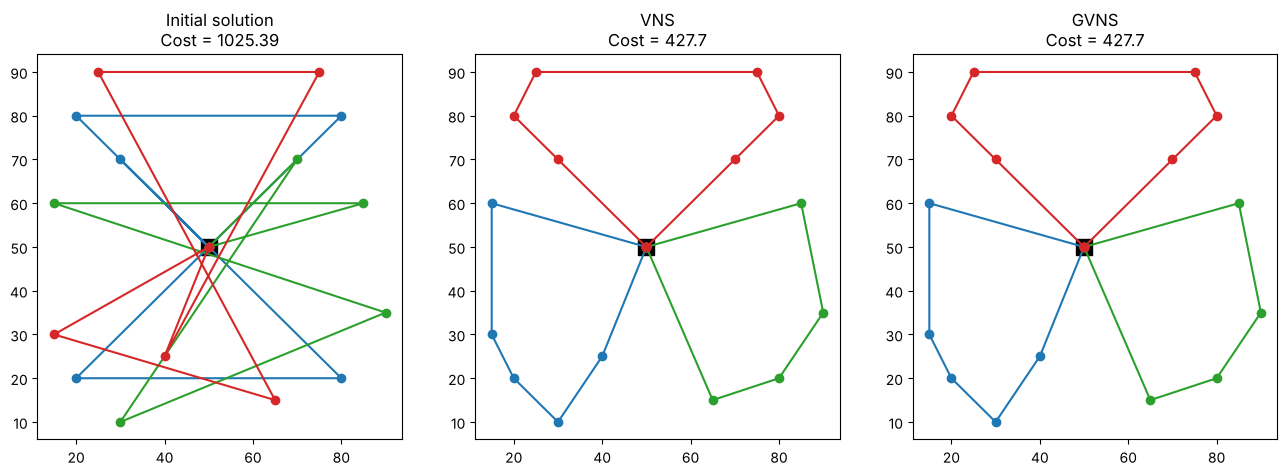

In [13]:
def plot_solution(solution, title, ax):

    colors = ["tab:blue", "tab:green", "tab:red"]

    for route, color in zip(solution, colors):
        path = [0] + route + [0]
        xs = [points[i][0] for i in path]
        ys = [points[i][1] for i in path]
        ax.plot(xs, ys, "-o", color=color)

    ax.scatter(points[0][0], points[0][1], c="black", marker="s", s=120)
    ax.set_title(title + "\nCost = " + str(round(evaluate(solution), 2)))


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

plot_solution(initial_solution, "Initial solution", axes[0])
plot_solution(vns_solution, "VNS", axes[1])
plot_solution(gvns_solution, "GVNS", axes[2])

plt.show()

## Conclusion

The initial solution mixes customers from different areas, so the vehicles travel a long distance.

VNS and GVNS reorganize the routes: they move customers to the right vehicle, improve the order of visits, and respect the capacity of each vehicle.

GVNS uses two neighborhoods (relocate and swap) instead of one, so it explores more solutions than VNS.

Finally, we can conclude that the best routes are the ones given by the GVNS solution above.